MATRIZ DE CONFUCION PARA XGBOOST

Comparativa con pesos ponderados y SMOTE

Realizado con la ayuda de GEMINI


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import xgboost as xgb

# 1. Cargar dataset reducido y replicar división exacta
df_3 = pd.read_csv("/content/dataset3_reducido_pesos.csv")
X = df_3.drop(columns=["burnout_score", "peso"])
y = df_3["burnout_score"]
pesos = df_3["peso"]

X_encoded = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test, pesos_train, pesos_test = train_test_split(
    X_encoded, y, pesos, test_size=0.30, random_state=42, stratify=y
)

# 2. Curva de aprendizaje (TRAIN vs. TEST variando tamaño de entrenamiento)
fracciones = [0.2, 0.4, 0.6, 0.8, 1.0]
tamanos_muestra = []
acc_train_curva = []
acc_test_curva = []

n_total = len(X_train)

for frac in fracciones:
  n_sub = int(n_total * frac)
  if frac < 1.0:
    X_sub, _, y_sub, _, pesos_sub, _ = train_test_split(
        X_train,
        y_train,
        pesos_train,
        train_size=n_sub,
        random_state=42,
        stratify=y_train,
    )
  else:
    X_sub, y_sub, pesos_sub = X_train, y_train, pesos_train

  modelo_curva = xgb.XGBClassifier(
      n_estimators=100,
      learning_rate=0.3,
      max_depth=2,
      objective="binary:logistic",
      random_state=42,
      n_jobs=-1,
  )
  modelo_curva.fit(X_sub, y_sub, sample_weight=pesos_sub)

  pred_tr = modelo_curva.predict(X_sub)
  pred_te = modelo_curva.predict(X_test)

  tamanos_muestra.append(n_sub)
  acc_train_curva.append(accuracy_score(y_sub, pred_tr, sample_weight=pesos_sub))
  acc_test_curva.append(accuracy_score(y_test, pred_te, sample_weight=pesos_test))

# 3. Graficar (morado para TRAIN, verde para TEST)
fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=300)
ax.plot(
    tamanos_muestra,
    acc_train_curva,
    marker="o",
    color="#6a1b9a",
    linewidth=2,
    label="Entrenamiento (TRAIN)",
)
ax.plot(
    tamanos_muestra,
    acc_test_curva,
    marker="s",
    color="#2e7d32",
    linewidth=2,
    label="Prueba (TEST)",
)

ax.set_title("Curva de Aprendizaje - XGBoost Ponderado (Subconjunto)")
ax.set_xlabel("Tamaño del conjunto de entrenamiento (muestras)")
ax.set_ylabel("Exactitud ponderada")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("curva_aprendizaje_xgboost.png", dpi=300, bbox_inches="tight")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/dataset3_reducido_pesos.csv'

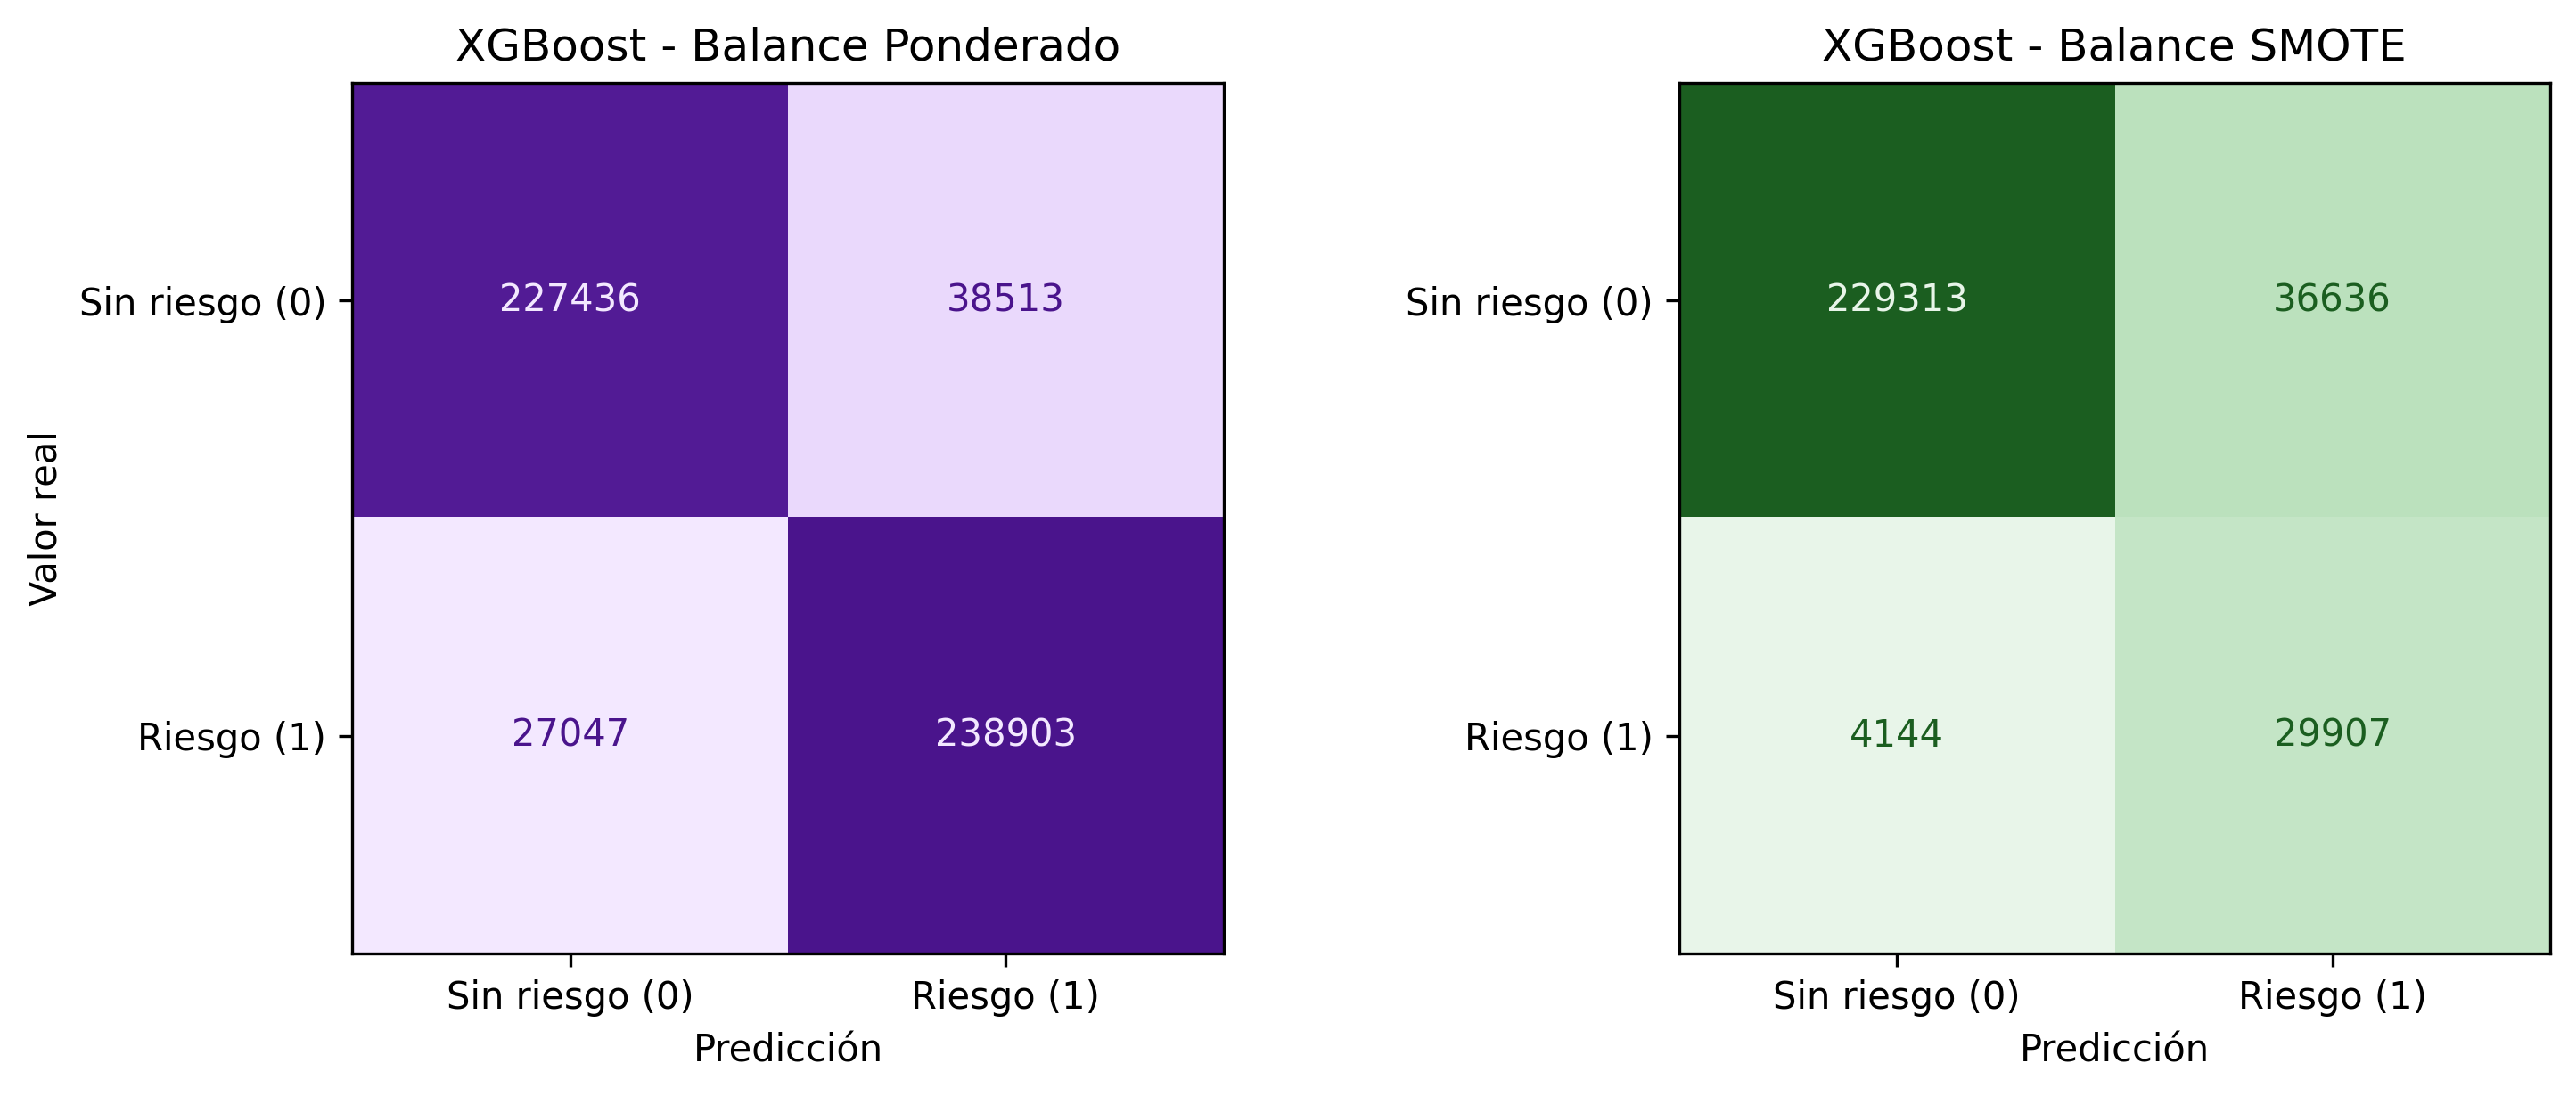

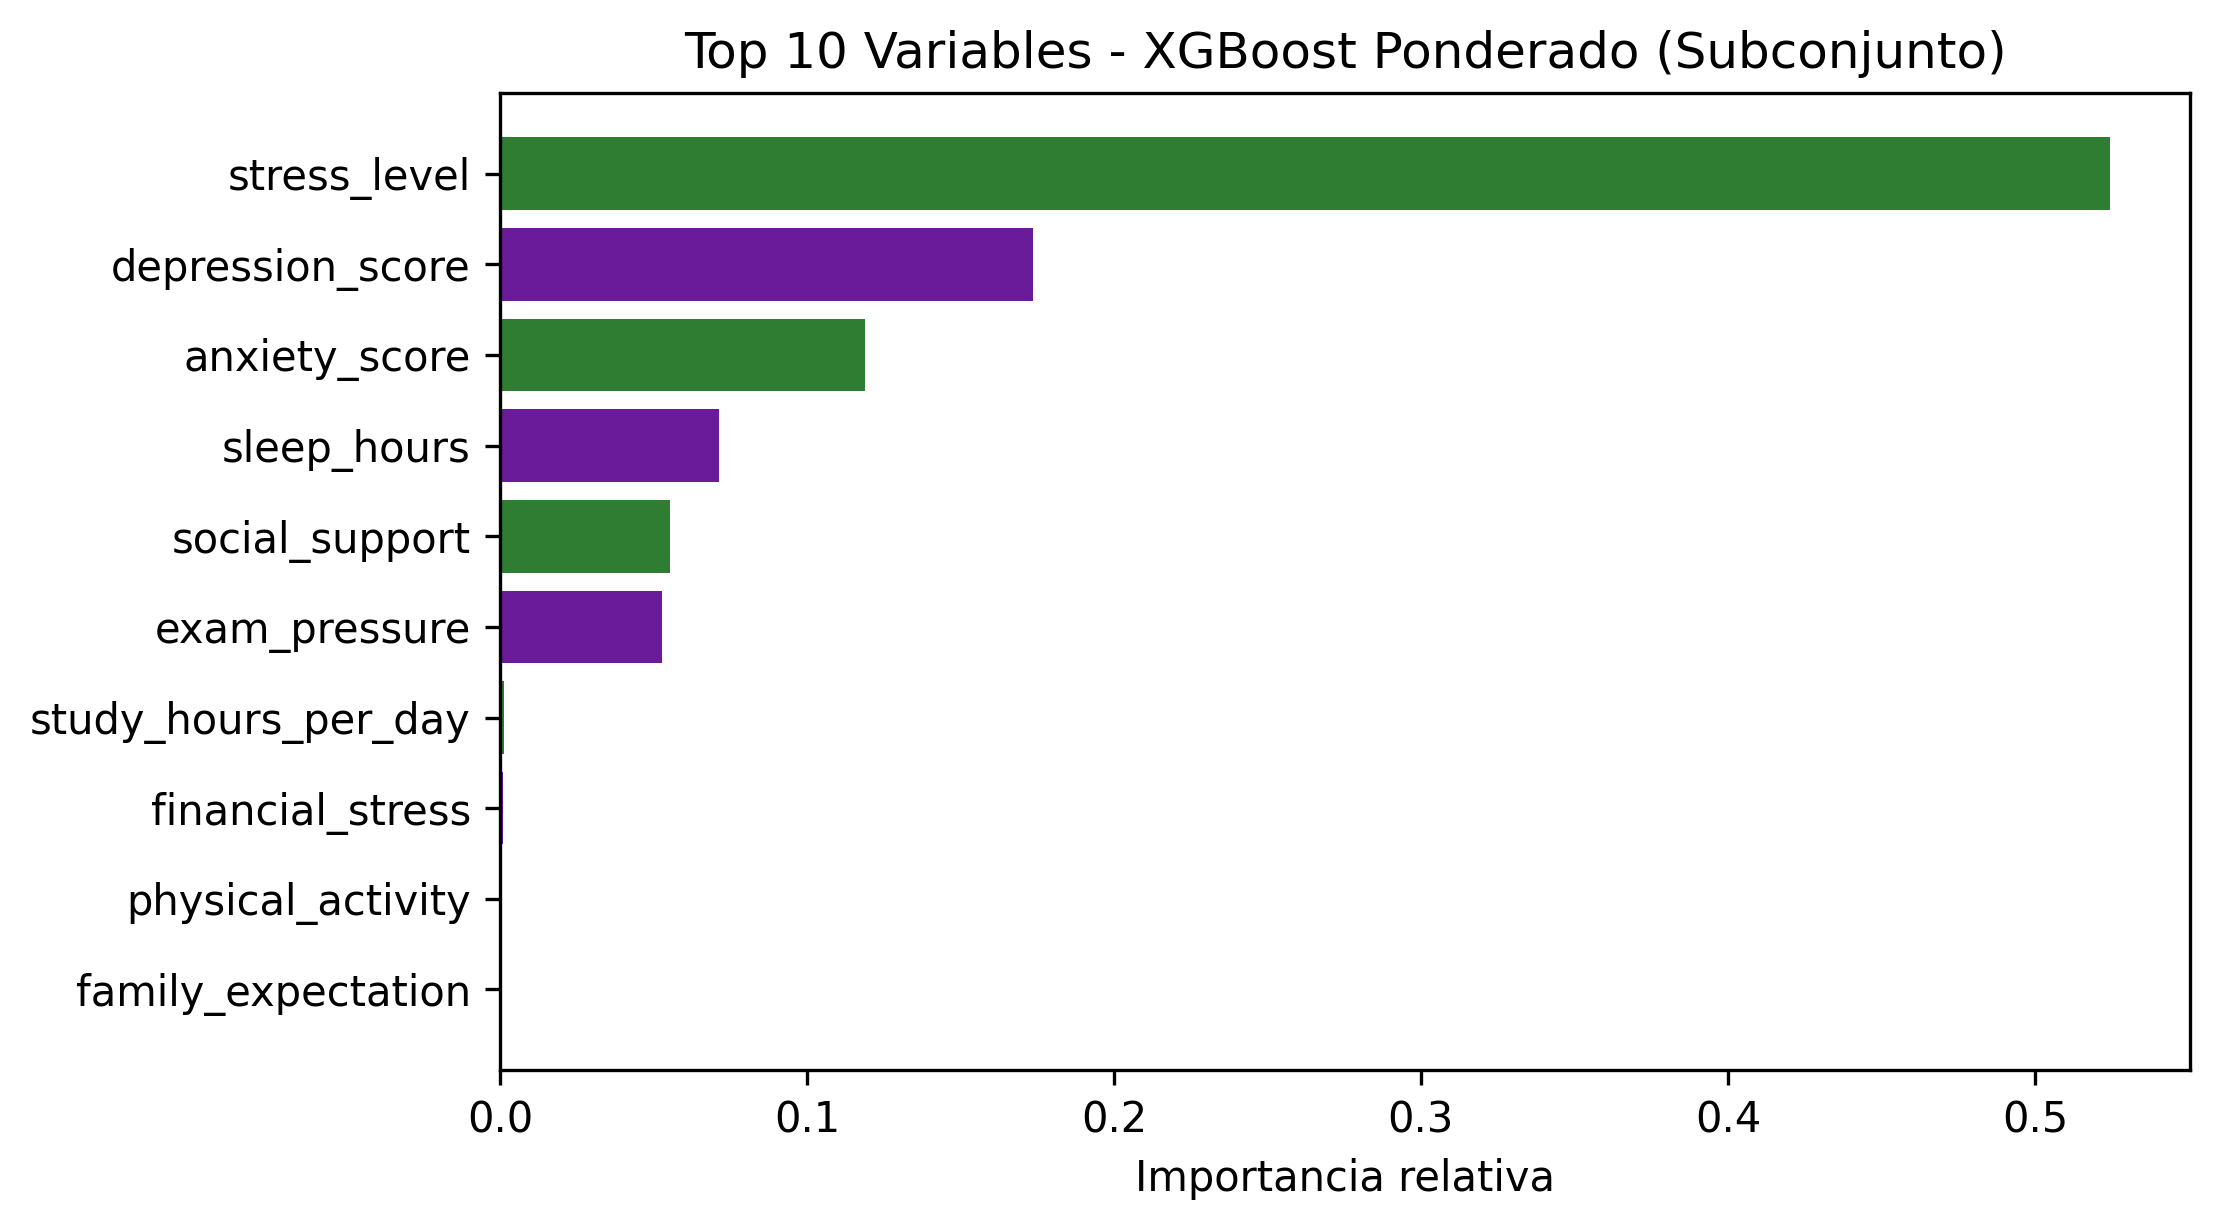

In [ ]:
from imblearn.over_sampling import SMOTE
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
import xgboost as xgb

# 1. Cargar dataset reducido y replicar división exacta
df_3 = pd.read_csv("/content/dataset3_reducido_pesos.csv")
X = df_3.drop(columns=["burnout_score", "peso"])
y = df_3["burnout_score"]
pesos = df_3["peso"]

X_encoded = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test, pesos_train, pesos_test = train_test_split(
    X_encoded, y, pesos, test_size=0.30, random_state=42, stratify=y
)

# 2. Modelo ganador con balance ponderado (max_depth=2)
xgb_pesos = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.3,
    max_depth=2,
    objective="binary:logistic",
    random_state=42,
    n_jobs=-1,
)
xgb_pesos.fit(X_train, y_train, sample_weight=pesos_train)
y_pred_pesos = xgb_pesos.predict(X_test)
cm_pesos = confusion_matrix(y_test, y_pred_pesos, sample_weight=pesos_test)

# 3. Modelo equivalente con SMOTE
smote = SMOTE(random_state=42)
X_train_balanceado, y_train_balanceado = smote.fit_resample(X_train, y_train)

xgb_smote = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0,
    objective="binary:logistic",
    random_state=42,
    n_jobs=-1,
)
xgb_smote.fit(X_train_balanceado, y_train_balanceado)
y_pred_smote = xgb_smote.predict(X_test)
cm_smote = confusion_matrix(y_test, y_pred_smote)

# Definicion de colores
cmap_morado = LinearSegmentedColormap.from_list(
    "morado_limpio", ["#f3e8ff", "#9b5de5", "#4a148c"]
)
cmap_verde = LinearSegmentedColormap.from_list(
    "verde_limpio", ["#e8f5e9", "#4caf50", "#1b5e20"]
)

# 4. Figura 1: Matrices de confusión lado a lado (morado y verde)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=300)

disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_pesos, display_labels=["Sin riesgo (0)", "Riesgo (1)"]
)
disp1.plot(ax=axes[0], cmap=cmap_morado, values_format=".0f", colorbar=False)
axes[0].set_title("XGBoost - Balance Ponderado")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Valor real")

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote, display_labels=["Sin riesgo (0)", "Riesgo (1)"]
)
disp2.plot(ax=axes[1], cmap=cmap_verde, values_format="d", colorbar=False)
axes[1].set_title("XGBoost - Balance SMOTE")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("matrices_confusion_xgboost.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Figura 2: Top 10 variables más importantes del modelo ganador (xgb_pesos)
importancias = xgb_pesos.feature_importances_
indices = np.argsort(importancias)[::-1][:10]
top_features = X_train.columns[indices]
top_scores = importancias[indices]

colores_barras = [
    "#6a1b9a" if i % 2 == 0 else "#2e7d32" for i in range(len(top_features))
]

fig2, ax2 = plt.subplots(figsize=(7.5, 4.2), dpi=300)
ax2.barh(range(len(top_features)), top_scores[::-1], color=colores_barras)
ax2.set_yticks(range(len(top_features)))
ax2.set_yticklabels(top_features[::-1])
ax2.set_xlabel("Importancia relativa")
ax2.set_title("Top 10 Variables - XGBoost Ponderado (Subconjunto)")
plt.tight_layout()
plt.savefig("importancia_variables_xgboost.png", dpi=300, bbox_inches="tight")
plt.show()